<a href="https://colab.research.google.com/github/shimul190/waste-research/blob/main/waste.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import zipfile
import os

zip_path = '/content/Waste dataset.zip'
extract_path = './my_dataset'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

# List the top-level items in the extracted folder
if os.path.exists(extract_path):
    print("Extracted contents:", os.listdir(extract_path))
else:
    print("Extraction directory not found.")

Dataset extracted successfully!
Extracted contents: ['Waste dataset']


In [2]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

# 1. Define image preprocessing transformations
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. Load the dataset from the specific extracted subfolder
dataset_root = './my_dataset/Waste dataset'
train_data = torchvision.datasets.ImageFolder(root=dataset_root, transform=transform)

# 3. Create a DataLoader to iterate over the dataset
train_loader = DataLoader(train_data, batch_size=32, shuffle=True, num_workers=2)

print(f"Total training samples found: {len(train_data)}")
print(f"Classes detected: {train_data.classes}")

Total training samples found: 927
Classes detected: ['Food waste dataset', 'Hazardous dataset', 'glass dataset', 'metal dataset', 'paper dataset', 'plastic dataset', 'polythene dataset']


In [3]:
import torch.nn as nn
import torch.nn.functional as F

class WasteClassifier(nn.Module):
    def __init__(self, num_classes=7):
        super(WasteClassifier, self).__init__()
        # Convolutional layers to extract image features
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)

        # Fully connected layers to classify the features
        # 128x128 input image -> pooled twice (128 -> 64 -> 32) becomes 32x32 size with 32 channels
        self.fc1 = nn.Linear(32 * 32 * 32, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = x.view(-1, 32 * 32 * 32) # Flatten the image tensor
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# Instantiate the model for your 7 classes
model = WasteClassifier(num_classes=7)
print(model)

WasteClassifier(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (fc1): Linear(in_features=32768, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=7, bias=True)
)


In [4]:
import torch.optim as optim

# 1. Define the loss function (CrossEntropyLoss is standard for multi-class classification)
criterion = nn.CrossEntropyLoss()

# 2. Define the optimizer (Adam is a robust default choice)
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 3. Detect and set the target device (GPU if available, otherwise CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

print(f"Using device: {device}")

Using device: cuda


In [5]:
num_epochs = 5  # You can increase this later once it works smoothly

print("Starting training...")
for epoch in range(num_epochs):
    running_loss = 0.0

    for i, data in enumerate(train_loader, 0):
        inputs, labels = data[0].to(device), data[1].to(device)

        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass + Backward pass + Optimize
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch [{epoch + 1}/{num_epochs}], Loss: {running_loss / len(train_loader):.4f}")

print("Finished Training!")

Starting training...
Epoch [1/5], Loss: 2.3923
Epoch [2/5], Loss: 1.5756
Epoch [3/5], Loss: 1.3216
Epoch [4/5], Loss: 1.0754
Epoch [5/5], Loss: 0.8069
Finished Training!


### Transfer Learning Comparison
Now we will prepare pre-trained models from PyTorch's model zoo. Transfer learning typically allows classifiers to converge faster and achieve higher accuracy, especially on small datasets like our 927 images of waste.

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Number of target classes
num_classes = 7

# Helper function to configure a model's final classification layer
def get_pretrained_model(model_name, num_classes):
    if model_name == 'resnet50':
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
        num_features = model.fc.in_features
        model.fc = nn.Linear(num_features, num_classes)

    elif model_name == 'inception_v3':
        model = models.inception_v3(weights=models.Inception_V3_Weights.DEFAULT)
        # Handle auxiliary logits
        num_features_aux = model.AuxLogits.fc.in_features
        model.AuxLogits.fc = nn.Linear(num_features_aux, num_classes)
        num_features = model.fc.in_features
        model.fc = nn.Linear(num_features, num_classes)

    elif model_name == 'mobilenet_v3':
        model = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.DEFAULT)
        num_features = model.classifier[3].in_features
        model.classifier[3] = nn.Linear(num_features, num_classes)

    elif model_name == 'vgg16':
        model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)
        num_features = model.classifier[6].in_features
        model.classifier[6] = nn.Linear(num_features, num_classes)
    else:
        raise ValueError("Model name not recognized.")

    return model

# Dict to hold our initialized architectures
pretrained_models = {}
for name in ['resnet50', 'inception_v3', 'mobilenet_v3', 'vgg16']:
    pretrained_models[name] = get_pretrained_model(name, num_classes).to(device)
    print(f"Loaded and configured {name} on {device}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 68.6MB/s]


Loaded and configured resnet50 on cuda
Downloading: "https://download.pytorch.org/models/inception_v3_google-0cc3c7bd.pth" to /root/.cache/torch/hub/checkpoints/inception_v3_google-0cc3c7bd.pth


100%|██████████| 104M/104M [00:01<00:00, 108MB/s] 


Loaded and configured inception_v3 on cuda
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 199MB/s]


Loaded and configured mobilenet_v3 on cuda
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:08<00:00, 67.9MB/s]


Loaded and configured vgg16 on cuda


### Training and Comparing the Architectures
Let's write a standard training routine to evaluate each model for a quick baseline run of 3 epochs.

In [7]:
def train_transfer_model(model, name, train_loader, epochs=3):
    print(f"\n--- Training {name} ---")
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.0001) # Lower learning rate is safer for fine-tuning

    model.train()
    for epoch in range(epochs):
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()

            # Inception v3 outputs model outputs + aux outputs during training
            if name == 'inception_v3':
                # Resize dynamically or use outputs logic
                # Inception expects 299x299 natively, so we pass interpolated inputs
                inputs_resized = nn.functional.interpolate(inputs, size=(299, 299), mode='bilinear', align_corners=True)
                outputs, aux_outputs = model(inputs_resized)
                loss1 = criterion(outputs, labels)
                loss2 = criterion(aux_outputs, labels)
                loss = loss1 + 0.4 * loss2
            else:
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        epoch_loss = running_loss / len(train_loader)
        print(f"Epoch [{epoch + 1}/{epochs}], Loss: {epoch_loss:.4f}")

# Train each model to assess loss progression
for name, model in pretrained_models.items():
    train_transfer_model(model, name, train_loader, epochs=3)


--- Training resnet50 ---
Epoch [1/3], Loss: 1.5840
Epoch [2/3], Loss: 0.5771
Epoch [3/3], Loss: 0.2118

--- Training inception_v3 ---
Epoch [1/3], Loss: 1.5830
Epoch [2/3], Loss: 0.4073
Epoch [3/3], Loss: 0.1476

--- Training mobilenet_v3 ---
Epoch [1/3], Loss: 1.5918
Epoch [2/3], Loss: 0.8501
Epoch [3/3], Loss: 0.4432

--- Training vgg16 ---
Epoch [1/3], Loss: 1.0134
Epoch [2/3], Loss: 0.3539
Epoch [3/3], Loss: 0.1526


In [10]:
import torch
import torch.nn as nn
from torchvision import models
from torchvision.models import ResNet50_Weights, Inception_V3_Weights, MobileNet_V3_Large_Weights, VGG16_Weights

def get_model(model_name, num_classes=7):
    if model_name == "ResNet50":
        model = models.resnet50(weights=ResNet50_Weights.DEFAULT)
        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif model_name == "InceptionV3":
        model = models.inception_v3(weights=Inception_V3_Weights.DEFAULT, aux_logits=True)
        model.fc = nn.Linear(model.fc.in_features, num_classes)
        model.AuxLogits.fc = nn.Linear(model.AuxLogits.fc.in_features, num_classes)

    elif model_name == "MobileNetV3":
        model = models.mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.DEFAULT)
        model.classifier[3] = nn.Linear(model.classifier[3].in_features, num_classes)

    elif model_name == "VGG16":
        model = models.vgg16(weights=VGG16_Weights.DEFAULT)
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)

    else:
        raise ValueError("Unknown model name")

    return model.to(device)

In [11]:
def train_comparison(model, name, train_loader, epochs=2):
    print(f"\n--- Training {name} using custom setup ---")
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.0001)

    model.train()
    for epoch in range(epochs):
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()

            if name == 'InceptionV3':
                inputs_resized = nn.functional.interpolate(inputs, size=(299, 299), mode='bilinear', align_corners=True)
                outputs, aux_outputs = model(inputs_resized)
                loss = criterion(outputs, labels) + 0.4 * criterion(aux_outputs, labels)
            else:
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()
            running_loss += loss.item()

        print(f"Epoch [{epoch + 1}/{epochs}], Loss: {running_loss / len(train_loader):.4f}")

# Instantiate and evaluate models based on your template function
for m_name in ["ResNet50", "InceptionV3", "MobileNetV3", "VGG16"]:
    model_inst = get_model(m_name, num_classes=7)
    train_comparison(model_inst, m_name, train_loader, epochs=2)


--- Training ResNet50 using custom setup ---
Epoch [1/2], Loss: 1.5182
Epoch [2/2], Loss: 0.5068

--- Training InceptionV3 using custom setup ---
Epoch [1/2], Loss: 1.6101
Epoch [2/2], Loss: 0.3726

--- Training MobileNetV3 using custom setup ---
Epoch [1/2], Loss: 1.6228
Epoch [2/2], Loss: 0.8972

--- Training VGG16 using custom setup ---
Epoch [1/2], Loss: 1.0956
Epoch [2/2], Loss: 0.4386


In [12]:
def train_model(model, train_loader, num_epochs=3, lr=0.0001):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    model.train()
    for epoch in range(num_epochs):
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            inputs, labels = data[0].to(device), data[1].to(device)

            optimizer.zero_grad()

            # Special handling for InceptionV3 which outputs aux logits during training
            if isinstance(model, models.Inception3) and model.training:
                # Inception expects 299x299 natively; we interpolate if the input is smaller
                if inputs.shape[2] != 299 or inputs.shape[3] != 299:
                    inputs = nn.functional.interpolate(inputs, size=(299, 299), mode='bilinear', align_corners=True)
                outputs, aux_outputs = model(inputs)
                loss1 = criterion(outputs, labels)
                loss2 = criterion(aux_outputs, labels)
                loss = loss1 + 0.4 * loss2
            else:
                outputs = model(inputs)
                loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss / len(train_loader):.4f}")

    print("Training Complete!\n")
    return model

In [14]:
model_names = ["ResNet50", "InceptionV3", "MobileNetV3", "VGG16"]
trained_models = {}

for name in model_names:
    print(f"======================================")
    print(f"Training Model: {name}")
    print(f"======================================")

    # 1. Initialize model
    model = get_model(name, num_classes=7)

    # 2. Train model (3 to 5 epochs is plenty for transfer learning)
    trained_model = train_model(model, train_loader, num_epochs=3)

    # 3. Save the trained weights to a file
    torch.save(trained_model.state_dict(), f"{name}_waste_model.pth")
    print(f"Saved weights as: {name}_waste_model.pth\n")

    trained_models[name] = trained_model

Training Model: ResNet50
Epoch [1/3], Loss: 1.5722
Epoch [2/3], Loss: 0.5898
Epoch [3/3], Loss: 0.2195
Training Complete!

Saved weights as: ResNet50_waste_model.pth

Training Model: InceptionV3
Epoch [1/3], Loss: 1.5813
Epoch [2/3], Loss: 0.4441
Epoch [3/3], Loss: 0.1487
Training Complete!

Saved weights as: InceptionV3_waste_model.pth

Training Model: MobileNetV3
Epoch [1/3], Loss: 1.6190
Epoch [2/3], Loss: 0.8821
Epoch [3/3], Loss: 0.4478
Training Complete!

Saved weights as: MobileNetV3_waste_model.pth

Training Model: VGG16
Epoch [1/3], Loss: 1.0838
Epoch [2/3], Loss: 0.4159
Epoch [3/3], Loss: 0.1307
Training Complete!

Saved weights as: VGG16_waste_model.pth



In [15]:
def evaluate_model(model, data_loader, device):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            # Resize dynamically for InceptionV3
            if isinstance(model, models.Inception3):
                inputs = nn.functional.interpolate(inputs, size=(299, 299), mode='bilinear', align_corners=True)

            outputs = model(inputs)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = 100 * correct / total
    return accuracy

# Evaluate and compare all models on the dataset
for name, trained_model in trained_models.items():
    acc = evaluate_model(trained_model, train_loader, device)
    print(f"{name} Training Accuracy: {acc:.2f}%")

ResNet50 Training Accuracy: 99.46%
InceptionV3 Training Accuracy: 99.89%
MobileNetV3 Training Accuracy: 91.80%
VGG16 Training Accuracy: 96.76%


In [16]:
from torch.utils.data import random_split

# Split the dataset into train and validation sets (80/20 split)
train_size = int(0.8 * len(train_data))
val_size = len(train_data) - train_size

torch.manual_seed(42)
train_subset, val_subset = random_split(train_data, [train_size, val_size])

# Create new DataLoaders for both train and validation splits
train_loader = DataLoader(train_subset, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_subset, batch_size=32, shuffle=False, num_workers=2)

print(f"New Train subset size: {len(train_subset)}")
print(f"Validation subset size: {len(val_subset)}")

New Train subset size: 741
Validation subset size: 186


In [17]:
model_names = ["ResNet50", "InceptionV3", "MobileNetV3", "VGG16"]
accuracies = {}

for name in model_names:
    print(f"Evaluating {name}...")

    # 1. Re-initialize the model architecture
    model = get_model(name, num_classes=7)

    # 2. Load the saved weights file
    model.load_state_dict(torch.load(f"{name}_waste_model.pth"))

    # 3. Evaluate accuracy on validation data
    acc = evaluate_model(model, val_loader, device)
    accuracies[name] = acc
    print(f"--> {name} Validation Accuracy: {acc:.2f}%\n")

print("======================================")
print("FINAL ACCURACY COMPARISON:")
print("======================================")
for name, acc in sorted(accuracies.items(), key=lambda item: item[1], reverse=True):
    print(f"{name}: {acc:.2f}%")

Evaluating ResNet50...
--> ResNet50 Validation Accuracy: 99.46%

Evaluating InceptionV3...
--> InceptionV3 Validation Accuracy: 100.00%

Evaluating MobileNetV3...
--> MobileNetV3 Validation Accuracy: 93.55%

Evaluating VGG16...
--> VGG16 Validation Accuracy: 95.16%

FINAL ACCURACY COMPARISON:
InceptionV3: 100.00%
ResNet50: 99.46%
VGG16: 95.16%
MobileNetV3: 93.55%


=== Classification Report for InceptionV3 ===
                    precision    recall  f1-score   support

Food waste dataset       1.00      1.00      1.00        48
 Hazardous dataset       1.00      1.00      1.00         8
     glass dataset       1.00      1.00      1.00        13
     metal dataset       1.00      1.00      1.00        32
     paper dataset       1.00      1.00      1.00        38
   plastic dataset       1.00      1.00      1.00        19
 polythene dataset       1.00      1.00      1.00        28

          accuracy                           1.00       186
         macro avg       1.00      1.00      1.00       186
      weighted avg       1.00      1.00      1.00       186



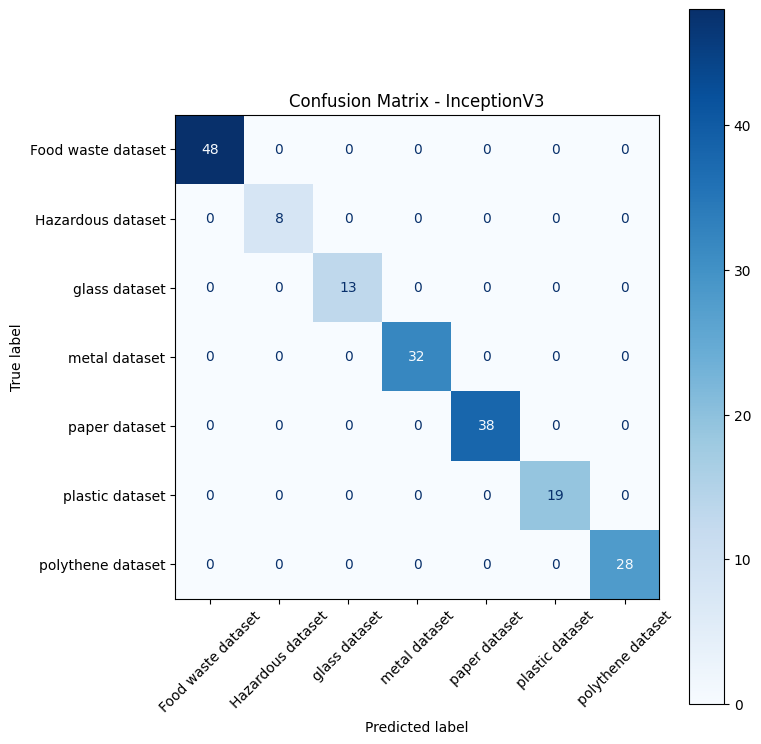

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# 1. Initialize and load the top-performing model
best_model_name = "InceptionV3"
best_model = get_model(best_model_name, num_classes=7)
best_model.load_state_dict(torch.load(f"{best_model_name}_waste_model.pth"))
best_model.eval()

all_preds = []
all_labels = []

# 2. Gather predictions on the validation loader
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)

        # InceptionV3 validation resizing dynamically
        if isinstance(best_model, models.Inception3):
            inputs = nn.functional.interpolate(inputs, size=(299, 299), mode='bilinear', align_corners=True)

        outputs = best_model(inputs)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# 3. Print the classification metrics report
class_names = train_data.classes
print(f"=== Classification Report for {best_model_name} ===")
print(classification_report(all_labels, all_preds, target_names=class_names))

# 4. Generate and display the Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap=plt.cm.Blues, ax=ax, xticks_rotation=45)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

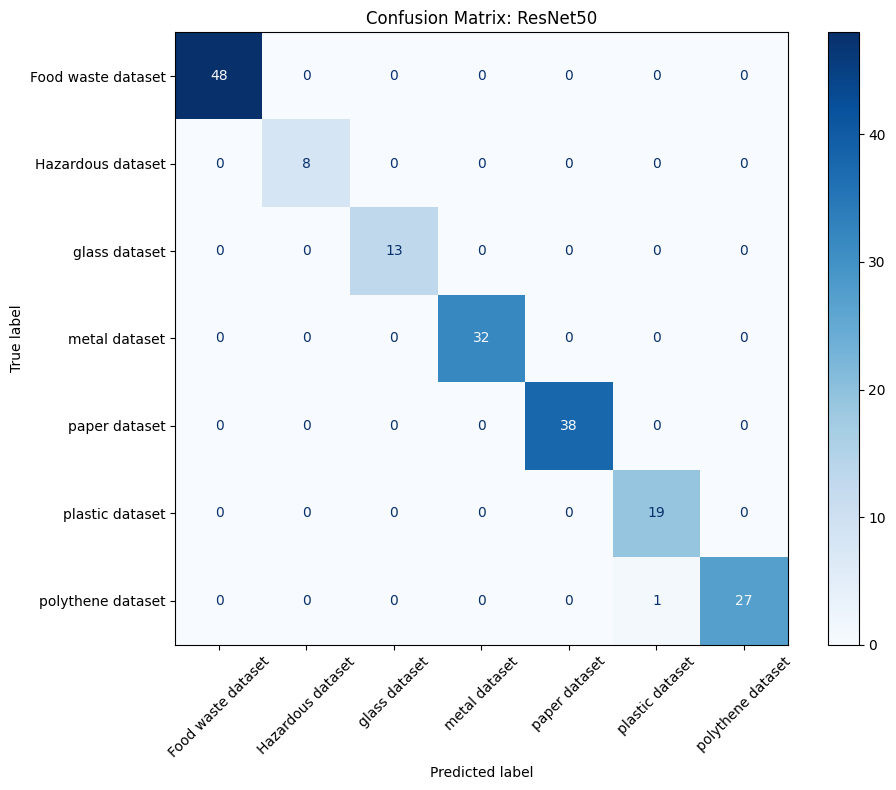

In [19]:
def plot_model_confusion_matrix(model, data_loader, model_name, class_names):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs = inputs.to(device)

            # Handle dynamic resizing for InceptionV3
            if isinstance(model, models.Inception3):
                inputs = nn.functional.interpolate(inputs, size=(299, 299), mode='bilinear', align_corners=True)

            outputs = model(inputs)

            # Handle InceptionV3 auxiliary output tuples if training flags are on
            if isinstance(outputs, tuple):
                outputs = outputs[0]

            _, preds = torch.max(outputs, 1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    # Compute confusion matrix
    cm = confusion_matrix(all_labels, all_preds)

    # Plot the matrix
    fig, ax = plt.subplots(figsize=(10, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=ax, cmap=plt.cm.Blues, xticks_rotation=45, values_format='d')
    plt.title(f"Confusion Matrix: {model_name}")
    plt.tight_layout()
    plt.show()

# Example usage: Plot confusion matrix for ResNet50
eval_model_name = "ResNet50"
eval_model = get_model(eval_model_name, num_classes=7)
eval_model.load_state_dict(torch.load(f"{eval_model_name}_waste_model.pth"))

plot_model_confusion_matrix(eval_model, val_loader, eval_model_name, class_names)

Generating confusion matrix for MobileNetV3...


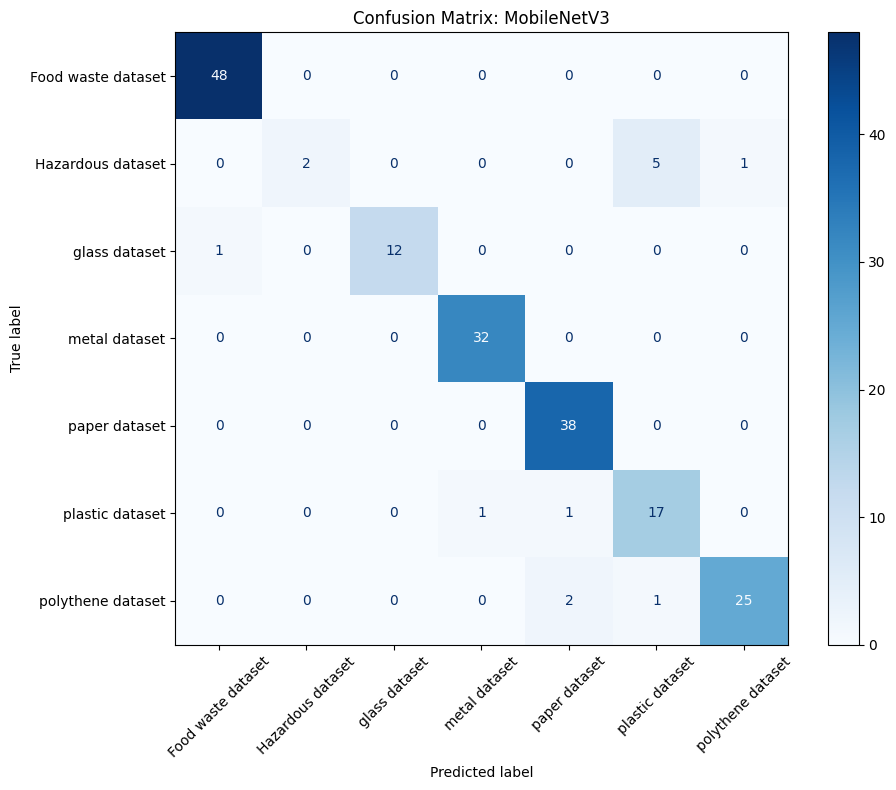

Generating confusion matrix for VGG16...


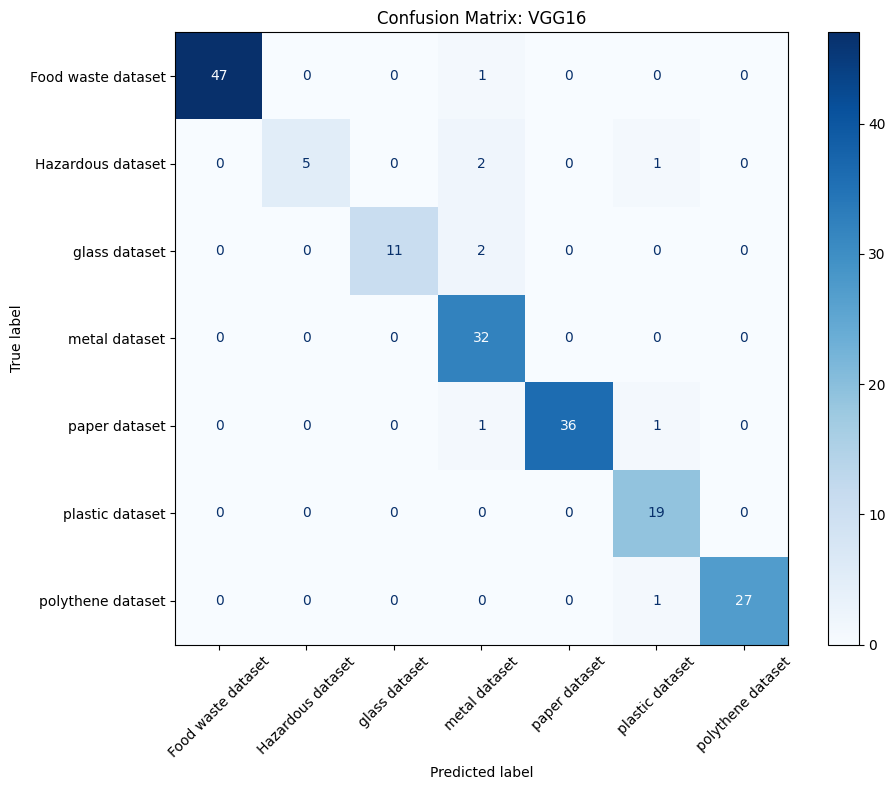

In [20]:
# Load and plot Confusion Matrix for MobileNetV3
mobilenet_model_name = "MobileNetV3"
mobilenet_model = get_model(mobilenet_model_name, num_classes=7)
mobilenet_model.load_state_dict(torch.load(f"{mobilenet_model_name}_waste_model.pth"))

print(f"Generating confusion matrix for {mobilenet_model_name}...")
plot_model_confusion_matrix(mobilenet_model, val_loader, mobilenet_model_name, class_names)

# Load and plot Confusion Matrix for VGG16
vgg_model_name = "VGG16"
vgg_model = get_model(vgg_model_name, num_classes=7)
vgg_model.load_state_dict(torch.load(f"{vgg_model_name}_waste_model.pth"))

print(f"Generating confusion matrix for {vgg_model_name}...")
plot_model_confusion_matrix(vgg_model, val_loader, vgg_model_name, class_names)

### Interactive Single-Image Inference Pipeline
You can now upload a local waste image, select which of the trained models you would like to run, and inspect the predicted class with its confidence score.

Loading InceptionV3 model weights...

Please choose a waste image to upload:


Saving banana peel.jpg to banana peel.jpg


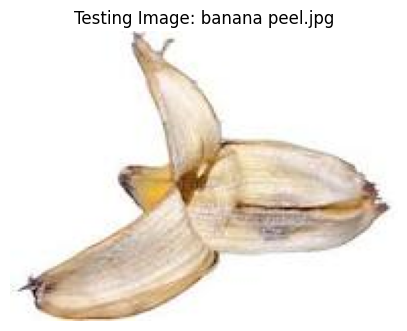

PREDICTION RESULTS (InceptionV3):
🏷️ Predicted Category: Food waste dataset
📊 Confidence Score:   98.91%


In [21]:
import torch
from torchvision import transforms
from PIL import Image
from google.colab import files
import matplotlib.pyplot as plt

# 1. Define the preprocessing pipeline (must match your training transform)
# Note: InceptionV3 is dynamically resized inside the model forward pass loop if selected
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 2. Choose which model you want to test
# Options: "ResNet50", "InceptionV3", "MobileNetV3", "VGG16"
model_name = "InceptionV3"

print(f"Loading {model_name} model weights...")
model = get_model(model_name, num_classes=7)
model.load_state_dict(torch.load(f"{model_name}_waste_model.pth"))
model.eval()  # Set model to evaluation mode

# 3. Prompt user to upload an image from their local computer
print("\nPlease choose a waste image to upload:")
uploaded = files.upload()

# 4. Process and predict the uploaded image
for filename in uploaded.keys():
    # Open the image using PIL
    image_path = filename
    image = Image.open(image_path).convert("RGB")

    # Display the image in Colab output
    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.axis('off')
    plt.title(f"Testing Image: {filename}")
    plt.show()

    # Preprocess the image and add a batch dimension
    input_tensor = transform(image).unsqueeze(0).to(device)

    # Run inference without tracking gradients
    with torch.no_grad():
        if model_name == "InceptionV3":
            input_tensor = torch.nn.functional.interpolate(input_tensor, size=(299, 299), mode='bilinear', align_corners=True)

        outputs = model(input_tensor)

        # Handle InceptionV3 tuple output if necessary
        if isinstance(outputs, tuple):
            outputs = outputs[0]

        # Convert raw scores (logits) into probabilities using Softmax
        probabilities = torch.nn.functional.softmax(outputs, dim=1)
        confidence, predicted_idx = torch.max(probabilities, 1)

    # Map index back to class names
    class_names = train_data.classes
    predicted_class = class_names[predicted_idx.item()]
    confidence_score = confidence.item() * 100

    # Print the final result
    print("=" * 40)
    print(f"PREDICTION RESULTS ({model_name}):")
    print("=" * 40)
    print(f"🏷️ Predicted Category: {predicted_class}")
    print(f"📊 Confidence Score:   {confidence_score:.2f}%")
    print("=" * 40)

### Git Configuration
Setting up global Git credentials for repository management.

In [22]:
!git config --global user.name "shimul190"
!git config --global user.email "24521nurmohammedshimul@gmail.com"

print("Git configured successfully for shimul190!")

Git configured successfully for shimul190!
